# A/B/C na training met schaal ×64

Deze notebook presenteert de vaste **post-hocevaluatie van de nieuwe schaal×64-training**. Tijdens deze training ontstond E2M3 via behoud van de hoogste exponentbits van E4M3, met blokschaal **64S**. E2M1 ontstond vervolgens door dezelfde mantissatruncatie vanuit E2M3. Dit is route **B**.

We gebruiken de twee oorspronkelijke checkpoints: **epoch 100** en het eerder gekozen **E4M3-best-checkpoint**. De epoch van die beste rol wordt uit de opgeslagen selectie gelezen; zij wordt niet opnieuw gekozen op A/B/C-accuracy. Op elk checkpoint worden de drie opgeslagen modi opnieuw gemeten en worden A, B en C uit dezelfde opgeslagen E4M3-bron bepaald.

**Route B is nu ook de reconstructiecontrole:** de opnieuw afgeleide B6/B4 moeten dezelfde codes, schalen en volledige inferentiemodelstaat hebben als de opgeslagen E2M3/E2M1-trainingsmodi. Historische herhaalverschillen en eventuele verschillen bij de CUDA-evaluatie worden apart getoond.

Verder plaatsen we de nieuwe scores naast de **eerder gemeten** A/B/C-resultaten van de directe en de naïeve training. Die oudere evaluaties worden niet opnieuw uitgevoerd. Elke trainingsrun behoudt haar eigen checkpoints en BN-statistieken.

**Activaties blijven A32; alle gewichten en batchnormstatistieken blijven bevroren.** De evaluator opent de zes FP32-updatemasters niet. De notebook leest uitsluitend JSON, CSV en NPZ en voert geen modelevaluatie, training, kalibratie of nieuwe selectie uit.

## 1. Resultaatmap

Open bij voorkeur de kopie in de nieuwe evaluatiemap. Vul anders hieronder het volledige pad naar die map in. Zij bevat `run_report.json`, `metrics.csv`, de map `scale64` met per-beeldresultaten en de map `prior_posthoc` met de bewaarde eerdere vergelijking.

`SAVE_FIGURES = False` toont alle figuren zonder analysebestanden te schrijven. Met `True` worden PNG- en PDF-versies in een nieuwe analysemap bewaard. De ruwe resultaten en de lege notebook blijven behouden; er wordt geen uitgevoerde notebook opgeslagen.

In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_scale64_trained_posthoc_eval\\20261024_173906_290709_evaluate')
SAVE_FIGURES = False  # Zet op True om PNG/PDF in een nieuwe analysemap te bewaren.


In [2]:
import importlib.util
import sys
import pandas as pd
from IPython.display import display, Markdown

helper_path = RUN_DIR.resolve() / "notebook_support.py"
if not helper_path.is_file():
    helper_path = Path.cwd() / "notebook_support.py"
if not helper_path.is_file():
    raise FileNotFoundError("Plaats deze notebook en notebook_support.py samen in de evaluatiemap en stel RUN_DIR in.")
spec = importlib.util.spec_from_file_location("mx_scale64_trained_notebook_support", helper_path)
ns = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = ns
spec.loader.exec_module(ns)

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_colwidth", 70)
run = ns.load_run(RUN_DIR, verify_per_image=True)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.diagnostics_table(run))

**Post-hocevaluatie bevestigd.** De schaal×64-training is op twee vaste checkpointrollen met negen routes per groep gecontroleerd.

Deze notebook leest opgeslagen resultaten. Zij voert geen modelevaluatie, training of BN-herkalibratie uit. De schaaloffset +6 is vooraf vastgelegd; er wordt geen schaal, route of checkpoint op deze resultaten geselecteerd.

,Niveau,Melding
0,LET OP,scale64/best_E4M3_test/trained4: herhaling verschilt +1 correcte b...
1,LET OP,scale64/last_epoch/source8: herhaling verschilt -1 correcte beelde...
2,LET OP,scale64/last_epoch/trained6: herhaling verschilt -1 correcte beeld...
3,LET OP,scale64/last_epoch/trained4: herhaling verschilt -1 correcte beeld...
4,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() is deprecated. Please...
5,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is deprecated. Please ...
6,RUNWAARSCHUWING,scale64/best_E4M3_test/trained4: +1 correcte voorspellingen tegeno...
7,RUNWAARSCHUWING,scale64/last_epoch/source8: -1 correcte voorspellingen tegenover h...
8,RUNWAARSCHUWING,scale64/last_epoch/trained6: -1 correcte voorspellingen tegenover ...
9,RUNWAARSCHUWING,scale64/last_epoch/trained4: -1 correcte voorspellingen tegenover ...


## 2. Wat vergelijken we?

Noem de opgeslagen E4M3-blokschaal **S** en de lokaal gedecodeerde E4M3-waarde **u**. Het brongewicht is **S × u**.

| Familie | E2M3-bewerking | Blokschaal | E2M1-bewerking |
|---|---|---|---|
| A | Behoud teken, hoogste twee van vier exponentbits en alle drie mantissabits | S | Verwijder de laagste twee mantissabits van A6 |
| B | Exact dezelfde elementcodes als A6 | 64S | Dezelfde mantissatruncatie vanuit B6 |
| C | Rond **u / 64** af naar E2M3, nearest-even | 64S | Dezelfde mantissatruncatie vanuit C6 |

**A → B** verandert alleen de schaal. **B → C** verandert alleen de elementmapping bij dezelfde vooraf vastgelegde schaal 64S. C leest uitsluitend de opgeslagen E4M3-codes: er wordt geen FP32-master geopend en geen nieuwe blokschaal berekend. De mantissatruncatie blijft in alle vierbitsroutes behouden.

Bij deze nieuwe training hoort B bij het aangeleerde gewichtspad. C is een **omzetting achteraf op een B-getraind model** met diens vaste BN-statistieken. Een verschil tussen C en B zegt daarom nog niet wat een met C getraind model zou bereiken. C is evenmin een bovengrens op de accuracy. A → B en B → C zijn concrete ingrepen in hetzelfde bevroren netwerk; hun accuracyeffecten vormen geen onafhankelijke causale optelsom.

In [3]:
display(ns.route_table())

,Route,Beschrijving,Doelbits,Activatiebits,BN-bank,Bewerking,Schaal
0,source8,"E4M3-bron, ongewijzigd",8,32,8,Herhaling opgeslagen E4M3-modus,E4M3-bronschaal S
1,trained6,E2M3 zoals getraind,6,32,32,Herhaling opgeslagen getrainde B-route,64 × E4M3-bronschaal S
2,trained4,E2M1 zoals getraind,4,32,4,Herhaling opgeslagen getrainde B-route,64 × E4M3-bronschaal S
3,A6,A · naïeve exponenttruncatie,6,32,32,Exponent-MSB-behoud,E4M3-bronschaal S
4,A4,A · exponent + mantissa,4,32,4,Exponent-MSB-behoud; daarna dezelfde mantissatruncatie E2M3 → E2M1,E4M3-bronschaal S
5,B6,"B · naïeve exponenttruncatie, schaal ×64",6,32,32,Exponent-MSB-behoud,64 × E4M3-bronschaal S
6,B4,"B · exponent + mantissa, schaal ×64",4,32,4,Exponent-MSB-behoud; daarna dezelfde mantissatruncatie E2M3 → E2M1,64 × E4M3-bronschaal S
7,C6,"C · afronden vanuit E4M3, schaal ×64",6,32,32,RNE_E2M3(decoded_E4M3 / 64),64 × E4M3-bronschaal S
8,C4,"C · afgeronde E2M3 → mantissa, schaal ×64",4,32,4,RNE_E2M3(decoded_E4M3 / 64); daarna dezelfde mantissatruncatie E2M...,64 × E4M3-bronschaal S


## 3. Hoofdresultaat: beide vaste checkpoints

De figuur toont **epoch 100** links en het eerder geselecteerde **E4M3-best-checkpoint** rechts. De lagere precisies gebruiken exact hetzelfde checkpoint als E4M3 binnen elk paneel. De getrainde referentiebalken worden in deze evaluatie opnieuw gemeten. B6/B4 reconstrueren hun oorspronkelijke gewichtspad; A6/A4 en C6/C4 veranderen dat pad achteraf.

De tabel toont percentages, correcte aantallen en hard cross-entropy. De controle bovenaan moet bevestigen dat alle achttien routes zijn gemeten. Ongeldige of onvolledige metrics worden niet als volledig eindresultaat voorgesteld.

,training,role,epoch,path,Beschrijving,weight_bits,correct1,n,top1_percent,hard_cross_entropy
9,scale64,last_epoch,100,source8,"E4M3-bron, ongewijzigd",8,24711,26032,94.925476,0.209864
10,scale64,last_epoch,100,trained6,E2M3 zoals getraind,6,24703,26032,94.894745,0.189966
11,scale64,last_epoch,100,trained4,E2M1 zoals getraind,4,24675,26032,94.787185,0.193794
12,scale64,last_epoch,100,A6,A · naïeve exponenttruncatie,6,2882,26032,11.070990,2.276989
13,scale64,last_epoch,100,A4,A · exponent + mantissa,4,2882,26032,11.070990,2.277239
14,scale64,last_epoch,100,B6,"B · naïeve exponenttruncatie, schaal ×64",6,24703,26032,94.894745,0.189966
15,scale64,last_epoch,100,B4,"B · exponent + mantissa, schaal ×64",4,24675,26032,94.787185,0.193794
16,scale64,last_epoch,100,C6,"C · afronden vanuit E4M3, schaal ×64",6,18626,26032,71.550400,1.214685
17,scale64,last_epoch,100,C4,"C · afgeronde E2M3 → mantissa, schaal ×64",4,18762,26032,72.072833,1.333761
0,scale64,best_E4M3_test,42,source8,"E4M3-bron, ongewijzigd",8,24753,26032,95.086816,0.193875


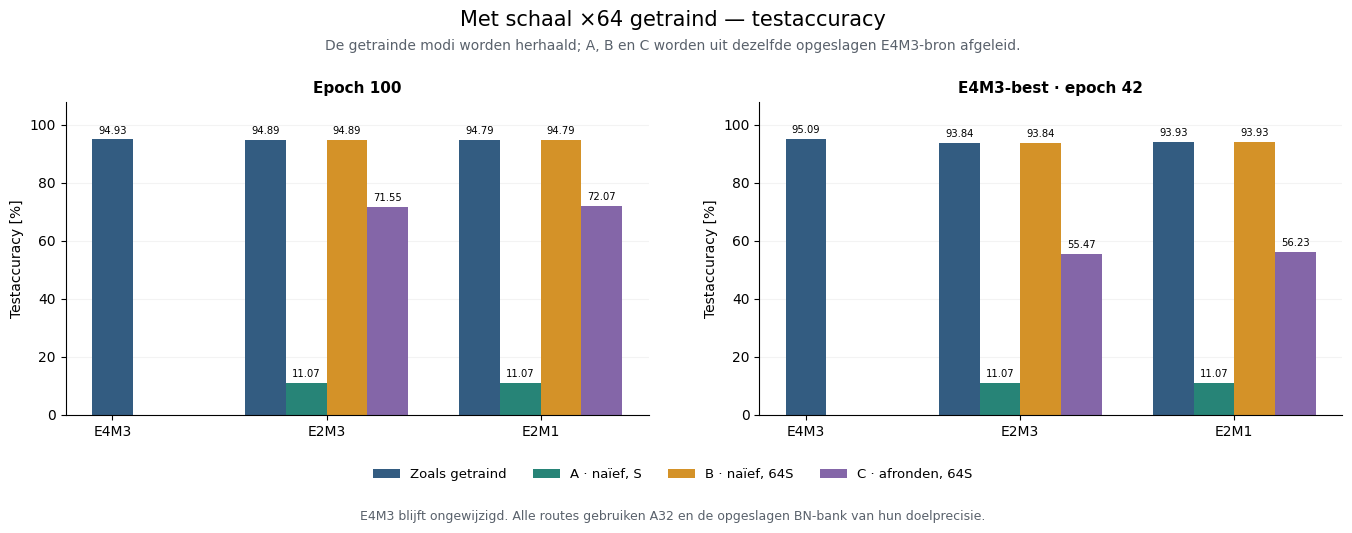

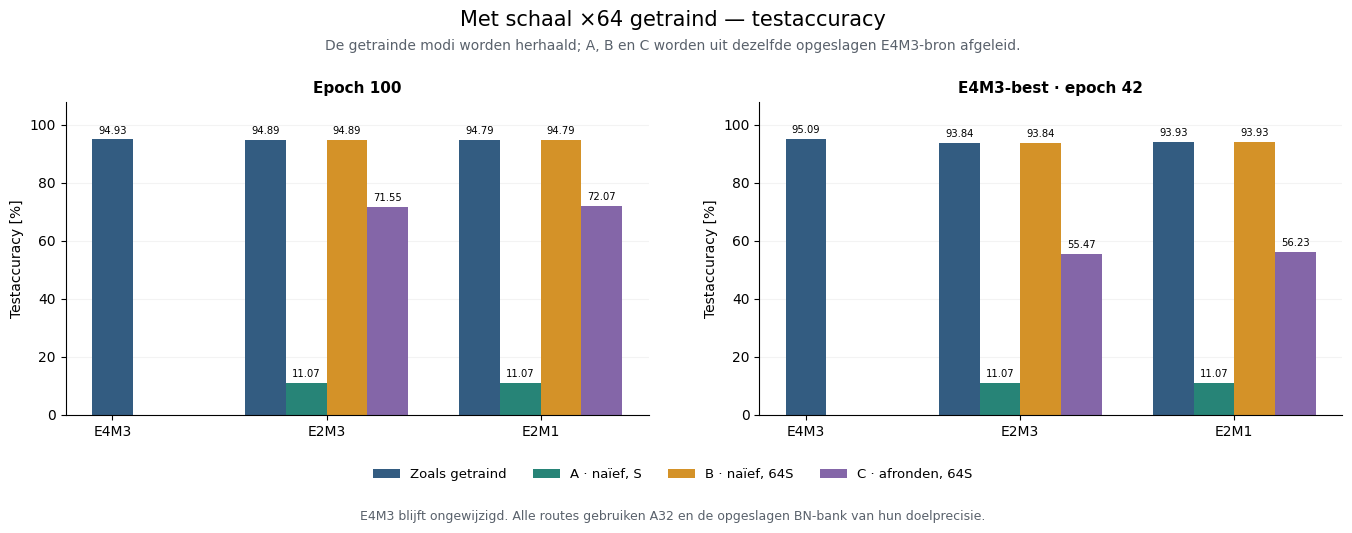

In [4]:
display(ns.accuracy_table(run))
figures["accuracy_scale64"] = ns.plot_checkpoint_accuracy(run, "scale64")
display(figures["accuracy_scale64"])

## 4. Afzonderlijke verschillen: schaal en afronding

Een positieve balk betekent een hogere accuracy bij de tweede route. **B − A** verandert de gedeelde schaal bij gelijke elementcodes. **C − B** verandert de elementmapping bij dezelfde schaal 64S. De volledige tabel bevat ook de verschillen met de opnieuw gemeten trainingsmodus en C − A.

Alle gepaarde verschillen in deze sectie horen bij **dezelfde schaal×64-training, hetzelfde checkpoint en dezelfde testbeelden**. De vergelijking met oudere trainingen staat in een afzonderlijke sectie en wordt beschrijvend gelezen.

,training,role,epoch,Vergelijking,Delta accuracy [pp],Netto correcte beelden
0,scale64,last_epoch,100,A6 − trained6,-83.823755,-21821
1,scale64,last_epoch,100,A4 − trained4,-83.716195,-21793
2,scale64,last_epoch,100,B6 − trained6,0.000000,0
3,scale64,last_epoch,100,B4 − trained4,0.000000,0
4,scale64,last_epoch,100,C6 − trained6,-23.344345,-6077
5,scale64,last_epoch,100,C4 − trained4,-22.714352,-5913
6,scale64,last_epoch,100,B6 − A6,83.823755,21821
7,scale64,last_epoch,100,B4 − A4,83.716195,21793
8,scale64,last_epoch,100,C6 − B6,-23.344345,-6077
9,scale64,last_epoch,100,C4 − B4,-22.714352,-5913


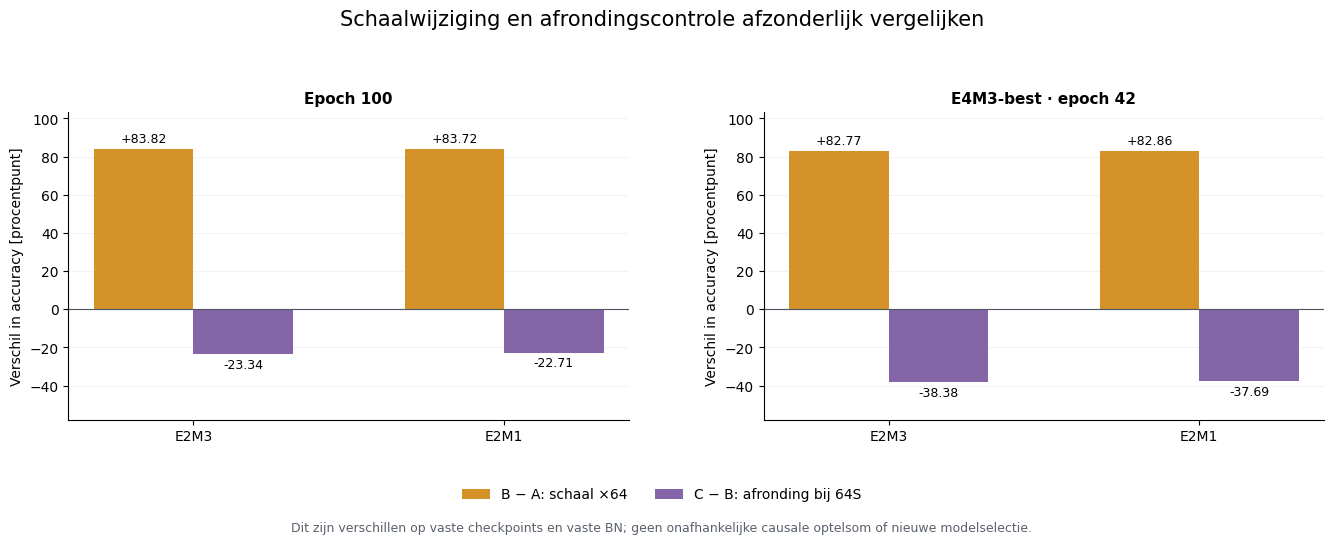

In [5]:
display(ns.delta_table(run))
figures["accuracy_deltas"] = ns.plot_accuracy_deltas(run)
display(figures["accuracy_deltas"])

## 5. Welke voorspellingen veranderen?

De figuur splitst elke vergelijking op in beelden die van fout naar correct gaan en beelden die van correct naar fout gaan. Het verschil tussen die twee aandelen is de accuracydelta. Ook veranderingen van het ene verkeerde cijfer naar een ander verkeerd cijfer worden in de tabel bijgehouden.

De helper controleert de opgeslagen per-beeldvoorspellingen en logits, de aantallen, de gemiddelde cross-entropy en alle gepaarde vergelijkingen opnieuw. Gelijke maximale logits zijn toegestaan: de door de evaluator opgeslagen topk-keuze hoeft bij een tie niet gelijk te zijn aan NumPy-argmax.

,Training,Rol,Epoch,Testbeelden,Checksum,Negen routes,Gepaarde tellingen
0,Met schaal ×64 getraind,last_epoch,100,26032,PASS,PASS,PASS
1,Met schaal ×64 getraind,best_E4M3_test,42,26032,PASS,PASS,PASS


,training,role,epoch,reference_path,other_path,prediction_changes,wrong_to_correct,correct_to_wrong,wrong_to_other_wrong,net_correct_change,accuracy_difference_pp
0,scale64,best_E4M3_test,42,trained6,A6,23144,212,21759,1173,-21547,-82.771205
1,scale64,best_E4M3_test,42,trained6,B6,0,0,0,0,0,0.000000
2,scale64,best_E4M3_test,42,trained6,C6,11604,404,10394,806,-9990,-38.375845
3,scale64,best_E4M3_test,42,trained4,A4,23097,199,21768,1130,-21569,-82.855716
4,scale64,best_E4M3_test,42,trained4,B4,0,0,0,0,0,0.000000
5,scale64,best_E4M3_test,42,trained4,C4,11328,358,10170,800,-9812,-37.692071
6,scale64,best_E4M3_test,42,A6,B6,23144,21759,212,1173,21547,82.771205
7,scale64,best_E4M3_test,42,A4,B4,23097,21768,199,1130,21569,82.855716
8,scale64,best_E4M3_test,42,B6,C6,11604,404,10394,806,-9990,-38.375845
9,scale64,best_E4M3_test,42,B4,C4,11328,358,10170,800,-9812,-37.692071


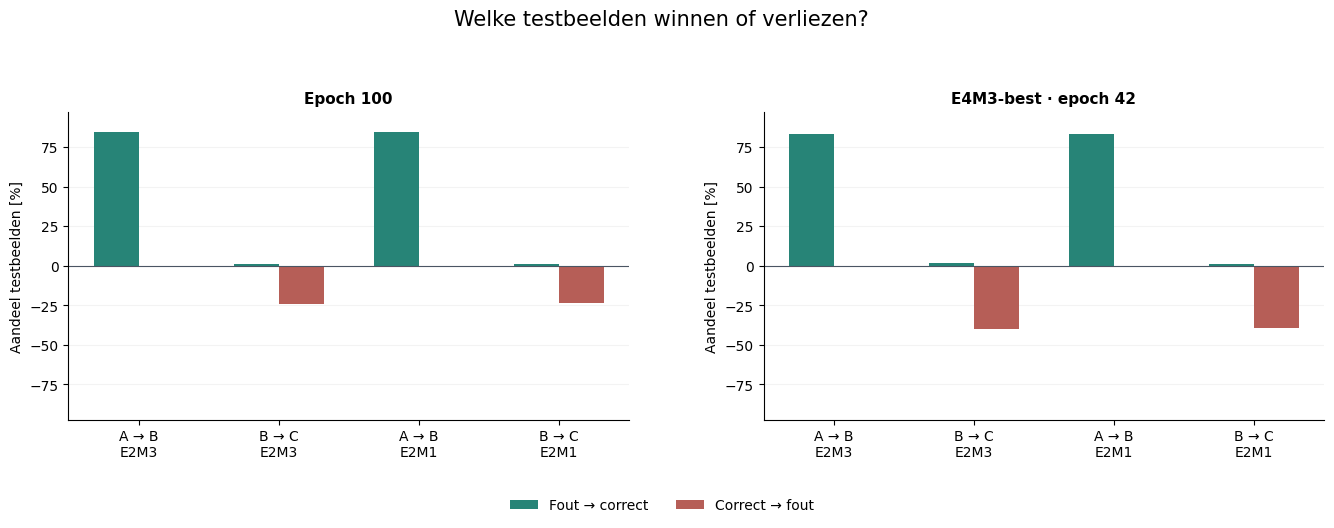

In [6]:
display(pd.DataFrame(run.output_checks))
if not run.pairs.empty:
    columns = [c for c in ["training", "role", "epoch", "reference_path", "other_path", "prediction_changes", "wrong_to_correct", "correct_to_wrong", "wrong_to_other_wrong", "net_correct_change", "accuracy_difference_pp"] if c in run.pairs]
    display(run.pairs[columns])
figures["paired_changes"] = ns.plot_paired_changes(run)
display(figures["paired_changes"])

## 6. Gewichtsgrootte en numerieke afwijking

Beide figuren gebruiken **dezelfde opgeslagen E4M3-bron** als gemeenschappelijke referentie per checkpoint. RMS laat de gewichtsgrootte zien; relatieve L2-afwijking is `||W_route − W_E4M3||₂ / ||W_E4M3||₂` per MX-laag. Een kleinere numerieke afwijking garandeert geen hogere accuracy. De FP32-master is geen referentie in deze proef.

Volle lijnen horen bij E2M3; stippellijnen bij E2M1. De laaglabels verwijzen naar de zes bestaande MX-convolutielagen. Bij een nulnorm kan een relatieve afwijking ongedefinieerd zijn; die wordt niet als nul ingevuld.

De samenvatting toont het bereik van de RMS-verhouding over de zes lagen en het totale aantal nulgewichten. A gebruikt S; B en C gebruiken doelbewust 64S. In de ruwe laagdiagnostiek verwijzen de historische veldnamen `*_to_direct` naar de **opgeslagen getrainde doelmodus van dezelfde training**, hier de met schaal ×64 getrainde modus. Cross-formaatcodebytes zijn geen vergelijkbare numerieke foutmaat.
Alle velden met `*_to_source` en alle schaaloffsets gebruiken nu dezelfde E4M3-bron als anker, ook voor de twee opgeslagen lagere trainingsmodi. Hun schaaloffset is dus +6; hun `*_to_direct`-referentie blijft de eigen opgeslagen doelmodus.


,training,role,path,rms_ratio_min,rms_ratio_max,nulgewichten,aantal_gewichten,schaaloffset
0,scale64,best_E4M3_test,source8,1.000000,1.000000,1,129472,0
1,scale64,best_E4M3_test,trained6,1.651556,2.393011,17,129472,6
2,scale64,best_E4M3_test,trained4,1.461622,2.090110,61,129472,6
3,scale64,best_E4M3_test,A6,0.025806,0.037391,17,129472,0
4,scale64,best_E4M3_test,A4,0.022838,0.032658,61,129472,0
5,scale64,best_E4M3_test,B6,1.651556,2.393011,17,129472,6
6,scale64,best_E4M3_test,B4,1.461622,2.090110,61,129472,6
7,scale64,best_E4M3_test,C6,1.000029,1.000214,4290,129472,6
8,scale64,best_E4M3_test,C4,0.885513,0.923326,23722,129472,6
9,scale64,last_epoch,source8,1.000000,1.000000,4,129472,0


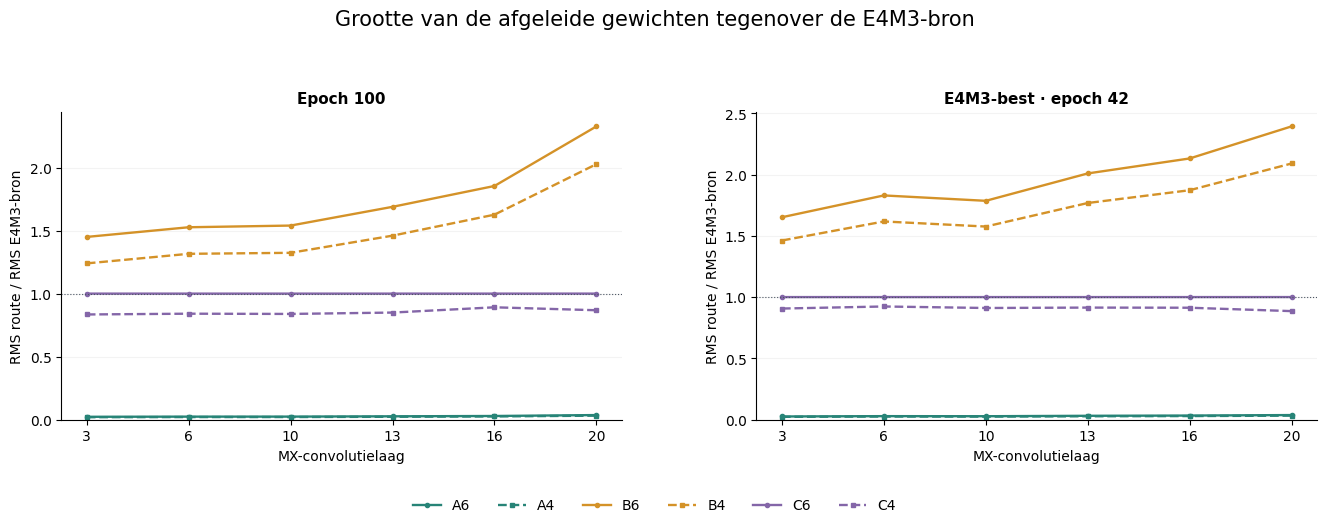

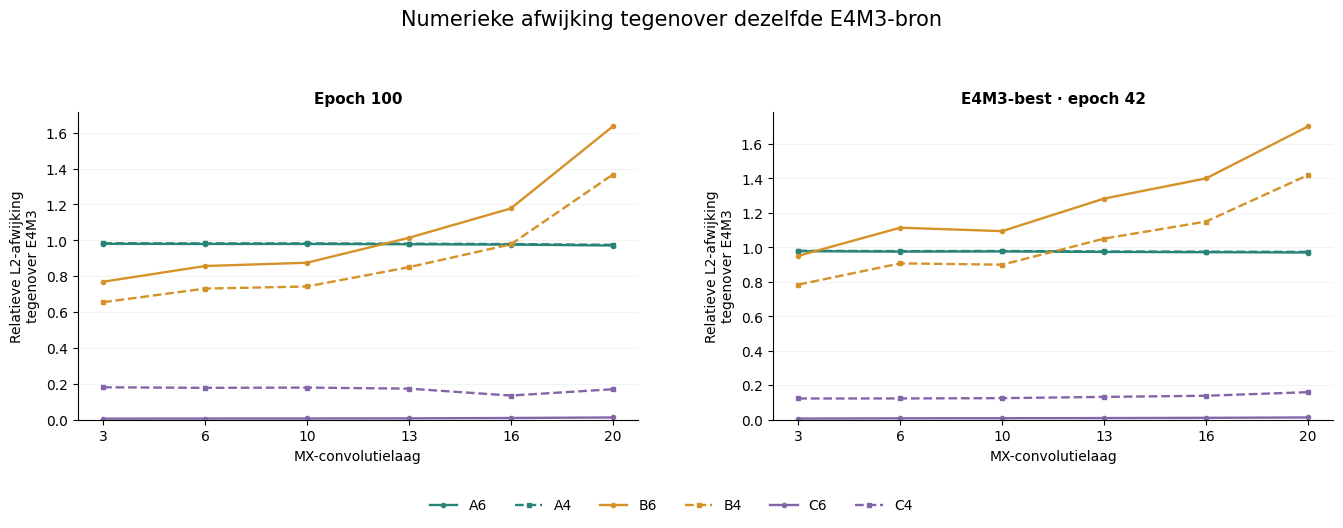

In [7]:
if not run.codes.empty and {"training", "role", "path", "rms_ratio_to_source", "zero_count", "n_weights", "scale_exponent_offset"} <= set(run.codes):
    code_summary = run.codes.groupby(["training", "role", "path"], sort=False).agg(
        rms_ratio_min=("rms_ratio_to_source", "min"), rms_ratio_max=("rms_ratio_to_source", "max"),
        nulgewichten=("zero_count", "sum"), aantal_gewichten=("n_weights", "sum"),
        schaaloffset=("scale_exponent_offset", "first")).reset_index()
    display(code_summary)
figures["weight_magnitudes"] = ns.plot_weight_magnitudes(run)
display(figures["weight_magnitudes"])
figures["weight_differences"] = ns.plot_weight_differences(run)
display(figures["weight_differences"])

## 7. Concentratie op één voorspelde klasse

Een lage accuracy kan samengaan met een vrijwel constante voorspelling. Daarom tonen we per route het aandeel van het meest voorspelde cijfer en het aantal verschillende voorspelde klassen. Eén klasse met 100% concentratie is een geldig gemeten resultaat; het is geen reden om die route uit de vergelijking te verwijderen.

Deze diagnose vervangt de accuracy niet. Zij helpt verklaren of een route nog gevarieerde voorspellingen produceert en of schaal ×64 of afronding dat patroon verandert.

,training,role,epoch,path,classes_predicted,dominant_class,dominant_fraction,n
0,scale64,last_epoch,100,source8,10,1,0.198141,26032
1,scale64,last_epoch,100,trained6,10,1,0.198141,26032
2,scale64,last_epoch,100,trained4,10,1,0.198563,26032
3,scale64,last_epoch,100,A6,1,3,1.000000,26032
4,scale64,last_epoch,100,A4,1,3,1.000000,26032
5,scale64,last_epoch,100,B6,10,1,0.198141,26032
6,scale64,last_epoch,100,B4,10,1,0.198563,26032
7,scale64,last_epoch,100,C6,10,8,0.247234,26032
8,scale64,last_epoch,100,C4,10,1,0.258221,26032
9,scale64,best_E4M3_test,42,source8,10,1,0.200177,26032


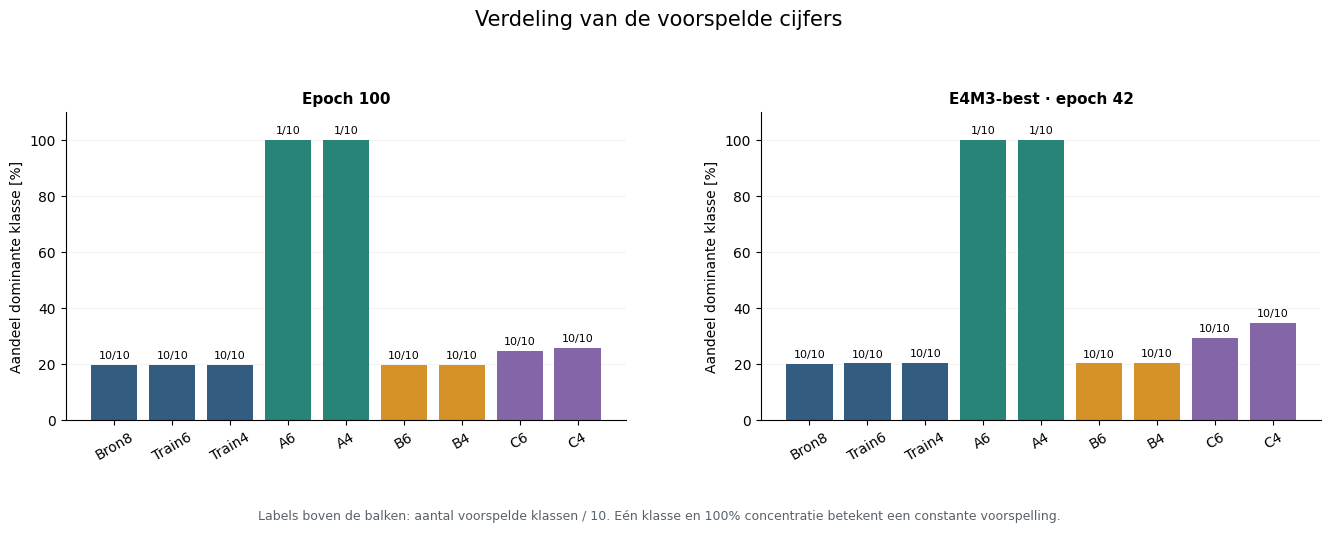

In [8]:
prediction_summary = ns.prediction_table(run)
if not prediction_summary.empty:
    display(prediction_summary[["training", "role", "epoch", "path", "classes_predicted", "dominant_class", "dominant_fraction", "n"]])
figures["prediction_diversity"] = ns.plot_prediction_diversity(run)
display(figures["prediction_diversity"])

## 8. De drie trainingsroutes naast elkaar

De eerste twee rijen van elke figuur komen uit de eerdere voltooide A/B/C-evaluatie: **direct getraind** en **naïef getraind met S**. De derde rij is de huidige evaluatie van het model dat **met B en 64S is getraind**. De meegeleverde historische CSV- en rapportbestanden worden op SHA256 en interne consistentie gecontroleerd. Zij worden niet opnieuw gemeten of aangepast.

Elk paneel houdt de oorspronkelijke checkpointrol aan. Bij **E4M3-best** kan de epoch per training verschillen; daarom staat zij bij iedere rij. De E4M3-kolom is steeds de bronreferentie van diezelfde training. De kolom «getraind» is de opnieuw gemeten oorspronkelijke lagere modus; de overige kolommen zijn de drie vaste omzettingen achteraf.

Lees deze vergelijking als een beschrijving van drie concrete trainingsruns. Zij bevat geen herhaalde seeds, geen nieuwe checkpointselectie en geen gepaarde interventie over trainingsruns. Een C-score op het nieuwe model meet een routeswitch na B-training, niet het resultaat van trainen met C.


,training,Training,Meetbron,role,epoch,path,weight_bits,correct1,n,top1_percent,hard_cross_entropy
9,direct,Direct getraind,Eerdere post-hocevaluatie,last_epoch,100,source8,8,24694,26032,94.860172,0.236220
10,direct,Direct getraind,Eerdere post-hocevaluatie,last_epoch,100,trained6,6,24732,26032,95.006146,0.200403
11,direct,Direct getraind,Eerdere post-hocevaluatie,last_epoch,100,trained4,4,24749,26032,95.071451,0.186247
12,direct,Direct getraind,Eerdere post-hocevaluatie,last_epoch,100,A6,6,4149,26032,15.938076,2.274756
13,direct,Direct getraind,Eerdere post-hocevaluatie,last_epoch,100,A4,4,4149,26032,15.938076,2.274692
...,...,...,...,...,...,...,...,...,...,...,...
40,scale64,Met schaal ×64 getraind,Deze post-hocevaluatie,best_E4M3_test,42,A4,4,2882,26032,11.070990,2.280322
41,scale64,Met schaal ×64 getraind,Deze post-hocevaluatie,best_E4M3_test,42,B6,6,24429,26032,93.842194,0.221278
42,scale64,Met schaal ×64 getraind,Deze post-hocevaluatie,best_E4M3_test,42,B4,4,24451,26032,93.926706,0.221426
43,scale64,Met schaal ×64 getraind,Deze post-hocevaluatie,best_E4M3_test,42,C6,6,14439,26032,55.466349,1.668160


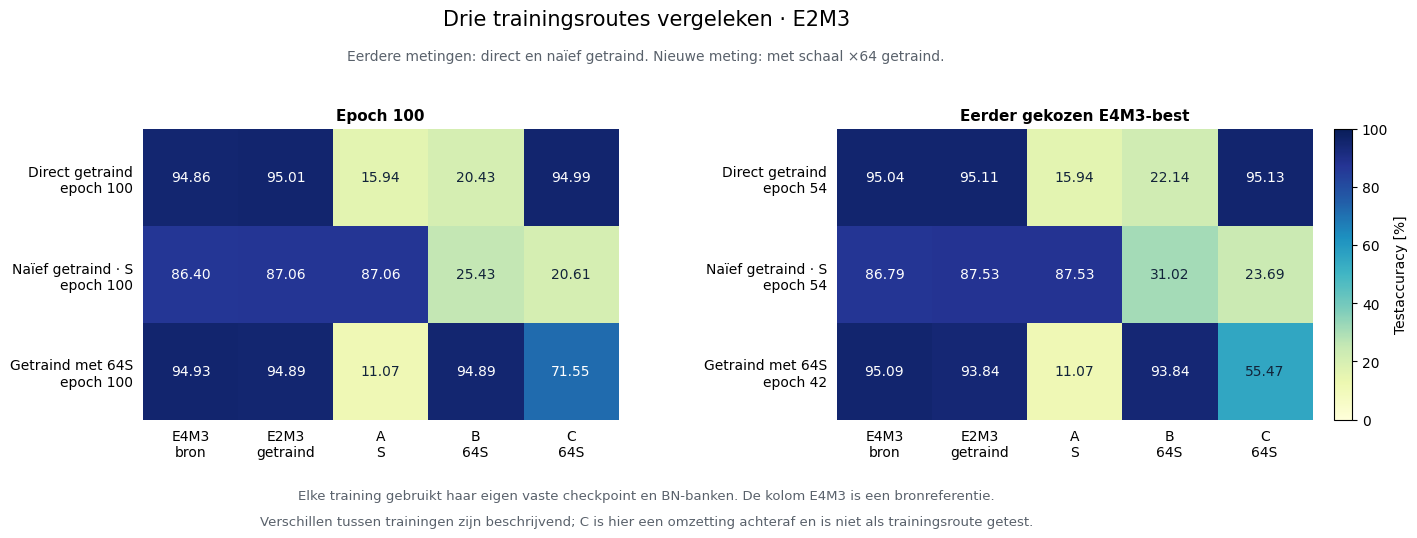

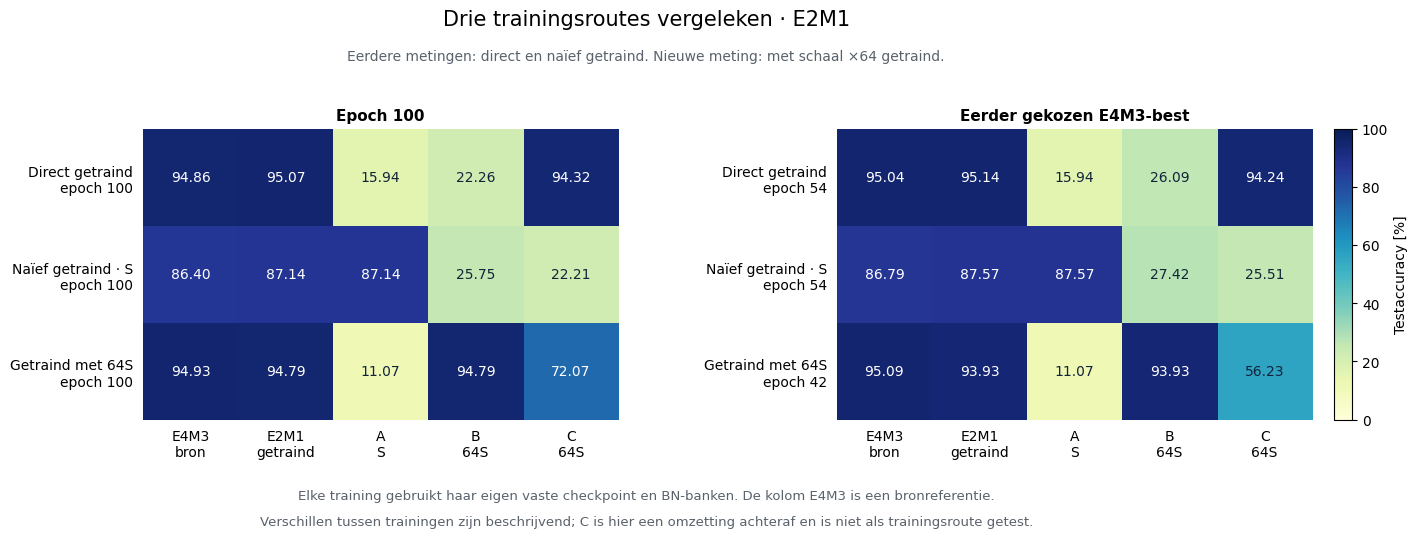

In [9]:
display(ns.historical_comparison_table(run))
figures["training_comparison_E2M3"] = ns.plot_training_comparison(run, 6)
display(figures["training_comparison_E2M3"])
figures["training_comparison_E2M1"] = ns.plot_training_comparison(run, 4)
display(figures["training_comparison_E2M1"])


## 9. Reconstructie van B, historische herhaling en vaste selectie

De eerste tabel is de eigen-routecontrole. Codes, schalen en inferentiemodelstaat van B6/B4 moeten exact overeenkomen met de opgeslagen E2M3/E2M1-modi. De opgeslagen logits worden daarnaast vergeleken met vaste toleranties (`rtol=1e-4`, `atol=1e-5`). Exacte logitgelijkheid, verschillen in voorspellingen en verschillen in correcte aantallen blijven zichtbaar. De oorspronkelijke CUDA-backend belooft geen bitexacte herhaling.

De tweede tabel vergelijkt de opnieuw gemeten oorspronkelijke modi met de historische trainingsscores. Een eventuele herhaalafwijking wordt gemeld en overschrijft het trainingsresultaat niet. Voor A/B/C blijven de actuele metingen op dezelfde testbeelden de referentie.

De audit bewaart de gekozen checkpointidentiteit en de vaste model- en BN-toestand. Er zijn nul optimizerupdates. Alleen de officiële testset wordt gebruikt; train- en extra-data worden niet ingelezen. De beste checkpointrol was eerder op de officiële testaccuracy van E4M3 gekozen en vormt dus geen onafhankelijk geselecteerde testschatting.

Bespreek eerst de B-reconstructie en historische herhaling, daarna A → B en B → C, en vervolgens de gewichts- en voorspeldiagnostiek. De resultaten bepalen welke vervolgvraag zinvol is; de notebook selecteert geen nieuwe winnaar, schaal of checkpoint.

In [10]:
display(ns.b_reproduction_table(run))
display(run.reproduction)
display(ns.audit_table(run))
display(Markdown(ns.timing_markdown(run)))
for limitation in run.report.get("limitations", []):
    display(Markdown("- " + str(limitation)))

,Rol,Epoch,Route,Codes exact,Schalen exact,Modelstaat exact,Logits exact,Logits binnen tolerantie,Voorspellingwijzigingen,Verschil correcte beelden,Maximaal logitverschil
0,last_epoch,100,B6,True,True,True,True,True,0,0,0.0
1,last_epoch,100,B4,True,True,True,True,True,0,0,0.0
2,best_E4M3_test,42,B6,True,True,True,True,True,0,0,0.0
3,best_E4M3_test,42,B4,True,True,True,True,True,0,0,0.0


,training,role,epoch,path,historical_correct1,reevaluated_correct1,difference_correct1,accuracy_difference_pp,historical_ce,reevaluated_ce,correct1_matches_history
0,scale64,best_E4M3_test,42,source8,24753,24753,0,0.000000,0.193877,0.193875,True
1,scale64,best_E4M3_test,42,trained6,24429,24429,0,0.000000,0.221279,0.221278,True
2,scale64,best_E4M3_test,42,trained4,24450,24451,1,0.003841,0.221426,0.221426,False
3,scale64,last_epoch,100,source8,24712,24711,-1,-0.003841,0.209868,0.209864,False
4,scale64,last_epoch,100,trained6,24704,24703,-1,-0.003841,0.189969,0.189966,False
5,scale64,last_epoch,100,trained4,24676,24675,-1,-0.003841,0.193797,0.193794,False


,Training,Rol,Epoch,Model/BN ongewijzigd,Geen gradients,Optimizerupdates,BN-herkalibratie,Zes masters afwezig,Checkpoint-SHA256
0,Met schaal ×64 getraind,last_epoch,100,True,True,0,False,True,0605299354c6eb8dbee48cc318a118f1572e98c133441593c99fc71dcb96217d
1,Met schaal ×64 getraind,best_E4M3_test,42,True,True,0,False,True,66bf06173c44203cf01056dacd989d8af8e1d06fb9cae15ae74fa2a218083826


**Gemeten evaluatiesessie: 0.30 minuten.** Deze tijd omvat alle routes en administratie. Het is geen native-MX-snelheids- of energiebenchmark.

- New measurements only on the B-trained model; earlier direct/A results are archived historical observations.

...

- One training seed; the two checkpoints of one run are not independent repetitions.

- FP32 decoded buffers emulate MX; no native-kernel speed or energy claim.

- Six quantized FP32 masters are absent; FP32 exception layers and BN auxiliary state remain.

- Low accuracy is an outcome, not a software FAIL; historical mismatches are reported.

- CUDA repeatability is not bit-exact under the original backend policy.

## 10. Figuren bewaren

Alleen de volgende cel schrijft analysebestanden wanneer `SAVE_FIGURES` op `True` staat. Zij bewaart acht PNG-figuren, acht PDF-figuren en herkomstinformatie in een nieuwe analysemap. Bestaande resultaten blijven ongewijzigd. Een ontbrekende of ongeldige meting blijft als zodanig zichtbaar.

In [11]:
if SAVE_FIGURES:
    saved_to = ns.save_figures(run, figures)
    print("Figuren bewaard in:", saved_to)
else:
    print("Figuren alleen getoond; geen analysebestanden geschreven.")

Figuren alleen getoond; geen analysebestanden geschreven.
